In [28]:
import pandas as pd
import numpy as np

chosen_year = "2019"


base_data = pd.read_pickle(f'./snp/{chosen_year}.pkl')
gainers_data = pd.read_pickle(f'./gain_lose/{chosen_year}_top_gainers.pkl')
gainers_log = gainers_data.map(lambda x: np.sign(x) * np.log(abs(x)+1) if np.issubdtype(type(x), np.number) else x)
losers_data = pd.read_pickle(f'./gain_lose/{chosen_year}_top_losers.pkl')
losers_log = losers_data.map(lambda x: np.sign(x) * np.log(abs(x)+1) if np.issubdtype(type(x), np.number) else x)



gainers_day_percentiles = [pd.read_pickle(f'./gain_lose_percentiles/{chosen_year}_gainers_{(i+1)*20}.pkl') for i in range(5)]
losers_day_percentiles = [pd.read_pickle(f'./gain_lose_percentiles/{chosen_year}_losers_{(i+1)*20}.pkl') for i in range(5)]


f1w_gainers_data_percentiles = [pd.read_pickle(f'./f1w_percentiles/{chosen_year}_gainers_{(i+1)*20}.pkl') for i in range(5)]
f1w_losers_data_percentiles = [pd.read_pickle(f'./f1w_percentiles/{chosen_year}_losers_{(i+1)*20}.pkl') for i in range(5)]

gainers_log

Price                             Adj Close     Close      High       Low  \
Date                      Ticker                                            
2019-01-02 00:00:00+00:00 A             NaN  4.178414  4.191519  4.172551   
                          AAPL          NaN  3.674774  3.680497  3.651737   
                          ABBV          NaN  4.323888  4.346088  4.314890   
                          ABT           NaN  4.205402  4.225884  4.199288   
                          ACGL          NaN  3.302849  3.314913  3.297317   
...                                     ...       ...       ...       ...   
2019-12-30 00:00:00+00:00 ROL           NaN  3.108911  3.114994  3.098396   
                          HAL           NaN  3.210890  3.227553  3.208935   
                          TSCO          NaN  4.524125  4.530070  4.513097   
                          BBY           NaN  4.432384  4.436775  4.420351   
                          EXPD          NaN  4.352136  4.354285  4.341447   

Price                                 Open     Volume  Day Percent Change  \
Date                      Ticker                                            
2019-01-02 00:00:00+00:00 A       4.190483  14.563762           -0.012107   
                          AAPL    3.655896  18.813795            0.019373   
                          ABBV    4.345872  15.748249           -0.021791   
                          ABT     4.217938  15.983100           -0.012565   
                          ACGL    3.309448  13.615108           -0.006803   
...                                    ...        ...                 ...   
2019-12-30 00:00:00+00:00 ROL     3.105127  14.211330            0.003962   
                          HAL     3.211281  16.021409           -0.000407   
                          TSCO    4.517930  14.009844            0.006263   
                          BBY     4.426953  14.234550            0.005496   
                          EXPD    4.347569  13.943025            0.004627   

Price                             Previous Close  Percent Change  \
Date                      Ticker                                   
2019-01-02 00:00:00+00:00 A                  NaN             NaN   
                          AAPL               NaN             NaN   
                          ABBV               NaN             NaN   
                          ABT                NaN             NaN   
                          ACGL               NaN             NaN   
...                                          ...             ...   
2019-12-30 00:00:00+00:00 ROL           3.102498        0.006714   
                          HAL           3.204619        0.006536   
                          TSCO          4.517716        0.006479   
                          BBY           4.426045        0.006415   
                          EXPD          4.346169        0.006045   

Price                             Next Day Close  ...  Percent 1 Week Growth  \
Date                      Ticker                  ...                          
2019-01-02 00:00:00+00:00 A             4.141465  ...               0.052777   
                          AAPL          3.572650  ...              -0.028774   
                          ABBV          4.290836  ...              -0.015788   
                          ABT           4.157796  ...              -0.000863   
                          ACGL          3.287655  ...               0.021904   
...                                          ...  ...                    ...   
2019-12-30 00:00:00+00:00 ROL                NaN  ...                    NaN   
                          HAL                NaN  ...                    NaN   
                          TSCO               NaN  ...                    NaN   
                          BBY                NaN  ...                    NaN   
                          EXPD               NaN  ...                    NaN   

Price                             Percent 1 to 2 Week Growth  \
Date  

Regression for dummy 20 percent
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.004
Model:                            OLS   Adj. R-squared:                  0.004
Method:                 Least Squares   F-statistic:                     26.98
Date:                Fri, 15 Nov 2024   Prob (F-statistic):           2.13e-07
Time:                        02:20:41   Log-Likelihood:                 9828.8
No. Observations:                6025   AIC:                        -1.965e+04
Df Residuals:                    6023   BIC:                        -1.964e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.006

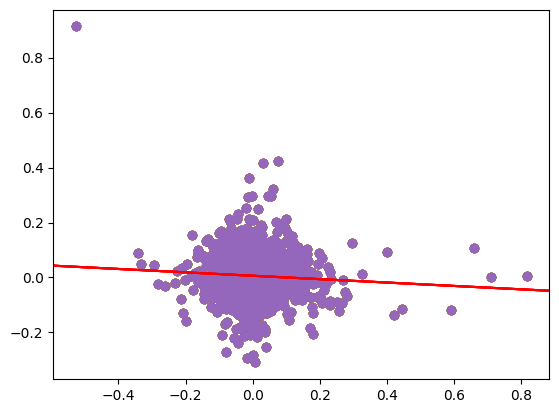

In [36]:
import statsmodels.api as sm
import numpy as np
import matplotlib.pyplot as plt

gainers_data_dummies = pd.get_dummies(pd.concat(gainers_day_percentiles, names=["Percent Change Dummy"], keys=[f'{(i+1)*20}' for i in range(len(gainers_day_percentiles))]).reset_index(level=0), columns=["Percent Change Dummy"])
gainers_data_dummies["Bottom 1 Week"] = gainers_data_dummies.index.isin(f1w_gainers_data_percentiles[-1].index)

# Ensure all data is numeric and drop rows with NaNs
for i in range(20,120,20):
    # X = gainers_data_dummies[[f"Percent Change Dummy_{i}", "Bottom 1 Week"]].apply(pd.to_numeric, errors='coerce')
    X = gainers_data_dummies["Percent 1 Week Growth"].apply(pd.to_numeric, errors='coerce')
    y = gainers_data_dummies["Percent 1 to 2 Week Growth"].apply(pd.to_numeric, errors='coerce')

    # Align X and y to ensure they have the same indices and drop NaNs
    X, y = X.align(y, join='inner', axis=0)

    # Drop NaNs
    X = X.dropna()
    y = y.loc[X.index]
    y = y.dropna()
    X = X.loc[y.index]

    # Ensure all data is numeric
    X = X.apply(pd.to_numeric, errors='coerce')
    y = y.apply(pd.to_numeric, errors='coerce')

    X = sm.add_constant(X)

    # Convert to numpy arrays
    X = np.asarray(X, dtype=np.float64)
    y = np.asarray(y, dtype=np.float64)

    print("Regression for dummy {} percent".format(i))
    results = sm.OLS(y, X).fit()
    print(results.summary())

    plt.scatter(gainers_data_dummies['Percent 1 Week Growth'], gainers_data_dummies['Percent 1 to 2 Week Growth'])
    fig = sm.graphics.abline_plot(model_results=results, color='red', ax=plt.gca())

    

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.003
Model:                            OLS   Adj. R-squared:                  0.003
Method:                 Least Squares   F-statistic:                     19.51
Date:                Fri, 15 Nov 2024   Prob (F-statistic):           1.02e-05
Time:                        02:08:58   Log-Likelihood:                 10184.
No. Observations:                6000   AIC:                        -2.036e+04
Df Residuals:                    5998   BIC:                        -2.035e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0059      0.001     10.275      0.0

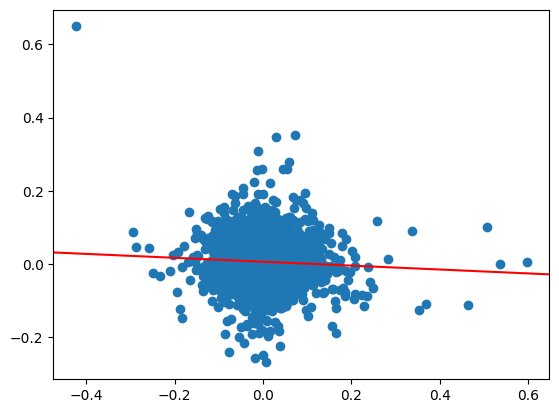

In [ ]:
# import statsmodels.api as sm
# import numpy as np

# gain_lose_dummies = gainers_log

# gain_lose_dummies_dropped = gain_lose_dummies.dropna(subset=["Percent 1 Week Growth", "Percent Change", "Percent 1 to 2 Week Growth"])

# X = gain_lose_dummies_dropped[["Percent 1 Week Growth"]].apply(pd.to_numeric, errors='coerce')
# y = gain_lose_dummies_dropped["Percent 1 to 2 Week Growth"].apply(pd.to_numeric, errors='coerce')

# # Align X and y to ensure they have the same indices and drop NaNs
# X, y = X.align(y, join='inner', axis=0)

# # Ensure all data is numeric
# X = X.apply(pd.to_numeric, errors='coerce')
# y = y.apply(pd.to_numeric, errors='coerce')

# X = sm.add_constant(X)

# # Convert to numpy arrays
# X = np.asarray(X, dtype=np.float64)
# y = np.asarray(y, dtype=np.float64)

# print(sm.OLS(y, X).fit().summary())

# results = sm.OLS(y, X).fit()

# import matplotlib.pyplot as plt
# plt.scatter(gain_lose_dummies_dropped['Percent 1 Week Growth'], gain_lose_dummies_dropped['Percent 1 to 2 Week Growth'])
# fig = sm.graphics.abline_plot(model_results=results, color='red', ax=plt.gca())

In [19]:
# import statsmodels.api as sm
# import numpy as np

# gain_lose_dummies = pd.concat([losers_data, gainers_data], names=["Loser"], keys=[True, False]).reset_index(level=0)

# gain_lose_dummies_dropped = gain_lose_dummies.dropna(subset=["Percent 1 Week Growth"])

# X = gain_lose_dummies_dropped["Loser"].apply(pd.to_numeric, errors='coerce')
# y = gain_lose_dummies_dropped["Percent 1 Week Growth"].apply(pd.to_numeric, errors='coerce')

# # Align X and y to ensure they have the same indices and drop NaNs
# X, y = X.align(y, join='inner', axis=0)

# # Drop NaNs
# # X = X.dropna()
# # y = y.loc[X.index]
# # y = y.dropna()
# # X = X.loc[y.index]



# # Ensure all data is numeric
# X = X.apply(pd.to_numeric, errors='coerce')
# y = y.apply(pd.to_numeric, errors='coerce')

# X = sm.add_constant(X)

# # Convert to numpy arrays
# X = np.asarray(X, dtype=np.float64)
# y = np.asarray(y, dtype=np.float64)

# print(sm.OLS(y, X).fit().summary())


In [20]:
# import statsmodels.api as sm
# import numpy as np


# gainer_tails_dummies = pd.concat([pd.concat([gainers_data_percentiles[0], gainers_data_percentiles[-1]], names=["Top_Tail"], keys=[True, False]).reset_index(level=0), pd.concat([losers_data_percentiles[0], losers_data_percentiles[-1]], names=["Top_Tail"], keys=[True, False]).reset_index(level=0)], names=["Gainer"], keys=[True, False]).reset_index(level=0)

# gainer_tails_dummies = gainer_tails_dummies.dropna(subset=["Percent 1 to 2 Week Growth"])


# X = gainer_tails_dummies[["Top_Tail", "Gainer"]].apply(pd.to_numeric, errors='coerce')
# y = gainer_tails_dummies["Percent 1 to 2 Week Growth"].apply(pd.to_numeric, errors='coerce')

# # Align X and y to ensure they have the same indices and drop NaNs
# X, y = X.align(y, join='inner', axis=0)

# # Drop NaNs
# # X = X.dropna()
# # y = y.loc[X.index]
# # y = y.dropna()
# # X = X.loc[y.index]



# # Ensure all data is numeric
# X = X.apply(pd.to_numeric, errors='coerce')
# y = y.apply(pd.to_numeric, errors='coerce')

# X = sm.add_constant(X)

# # Convert to numpy arrays
# X = np.asarray(X, dtype=np.float64)
# y = np.asarray(y, dtype=np.float64)

# print(sm.OLS(y, X).fit().summary())


In [21]:
# import statsmodels.api as sm
# import numpy as np

# data_wrangled = pd.concat([gainers_data, losers_data], names=["Gainer"], keys=[True, False]).reset_index(level=0)


# data_wrangled = data_wrangled.dropna(subset=["Percent 1 Week Growth", "Percent 1 to 2 Week Growth"])


# X = data_wrangled[["Percent 1 Week Growth", "Gainer"]]
# y = data_wrangled["Percent 1 to 2 Week Growth"]

# X = sm.add_constant(X)

# # Convert to numpy arrays
# X = np.asarray(X, dtype=np.float64)
# y = np.asarray(y, dtype=np.float64)

# print(sm.OLS(y, X).fit().summary())
